# Assignment 3: Bundle Adjustment 

### Required libraries

Please make sure you can import the following libraries before starting:

- NumPy
- OpenCV (cv2)
- Matplotlib
- SciPy

If you are using a custom environment, install missing packages before you begin.

---

### Submission instructions

- Complete **all** tasks in this notebook (code, plots, and written answers).
- Submit **only this completed Jupyter notebook** (`.ipynb`) on teams.
- Do **not** compress it into a `.zip` file or any other archive.
- Make sure every plot has:
  - properly labeled axes,
  - a legend when appropriate,
  - a short explanation (1–3 sentences) interpreting the result as well justifying them.
- Your notebook should run from top to bottom without errors on a clean environment. Dont say: "But prof, it works on my setup."

---

### On tools, integrity, and survival

- Emotional breakdowns are a respected academic tradition, but please maintain **basic fluid‑dynamics control**: if you need to cry, do it *adjacent* to the laptop, not *on* it. Tech, like self‑esteem, can be damaged.
- Using LLMs is allowed, but make sure to use **your own brain**: understand every line of code and every formula you submit. If you cannot explain it, you do not own it.
- Cheating (taking someone else's work) is strictly forbidden. If you’re caught, you will fail the course immediately. More importantly, you’ll have successfully lied to the one person you are stuck with for the rest of your life: yourself. The exam ends in 1h30; your relationship with your own integrity does not.



In this exercise you need to compute the bundle adjustment described in the lecture.
You're given the initial guess of the position of *four identical calibrated cameras* as well as *eight object points*, where each point is observed in each camera. Apart from that no further observations were made.
Assume the rotation matrices $R_j$ to be given with $R_j=I_3$. 
Therefore the rotations $\kappa, \theta, \omega$ are not included as unknowns in the bundle adjustment.
Furthermore assume all cameras to be *euclidian cameras*.

The file `data.mat` contains the calibration matrix `K`, initial estimations of the projection centers `camX_pos`, initial estimations of the object points `X` as well as observed image coordinates `camX_obs`, where the i'th observation corresponds to the i'th object.


**Tasks:**

1. Construct the initial parameter vector $\textbf{p}^{(0)}$ and vector of observations $\textbf{l}$. Which size would have the parameter vectors $\mathbf{\Delta k}$ and $\mathbf{\Delta t}$ from the lecture. (2 Points)
2. Given the initial parameters compute the approximated observations $\mathbf{l}^{(0)}.$
	Print out the computed euclidean image coordinates of the first point in each camera to the terminal. (5 Points)
3. 	Construct the coefficient matrix $\mathbf{A}^{(0)}$ given the initial parameters. Visualize the coefficient matrix by using `spy(...)` from matplotlib. The sub-matrices shown in the lecture are given by (10 Points):
$$
B_{ij} =
\frac{c}{\Delta Z_{ij}}
\begin{bmatrix}
-1 & 0 & \frac{\Delta X_{ij}}{\Delta Z_{ij}} \\
0 & -1 & \frac{\Delta Y_{ij}}{\Delta Z_{ij}}
\end{bmatrix}
$$

$$
C_{ij} =
\frac{c}{\Delta Z_{ij}}
\begin{bmatrix}
1 & 0 & \frac{-\Delta X_{ij}}{\Delta Z_{ij}} \\
0 & 1 & \frac{-\Delta Y_{ij}}{\Delta Z_{ij}}
\end{bmatrix}
$$

 4. Solve the normal equations $\hat{\mathbf p}=\mathbf{p}^{(0)}+(\mathbf{A}^T \mathbf{A})^{+} \mathbf{A}^T (\mathbf{l}-\mathbf{l}^{(0)})$.
	We assume uniform uncertainty in the image coordinates without any correlation.
	**Note:** $\mathbf{A}^{+}$ denotes the pseudoinverse of the matrix $\mathbf{A}$. (1 Point)
5. Visualize the initial and estimated parameters. Different parameters should've different colours. (3 Points)

**Note:** $\Delta X_{ij}= X_{i}-X_{0j}$, with  $X_i$= x-Coordinate of i'th object point, $X_{0j}$= x-Coordinate of projection center of j'th camera. $\Delta Y_{ij}$, $\Delta Z_{ij}$ analogue to this.

In [1]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
%matplotlib notebook

## Load data

In [2]:
data = scipy.io.loadmat('data/data.mat')

# Calibration matrix
K = data['K'].astype(np.float32)
c = K[0, 0]

# initial point coordinates
X = data['X0'].astype(np.float32) # [3 x 8]

# observations and initial projection centers
cameras = data['camera']
cam0_pos = cameras[0,0][0].astype(np.float32) # projection center [3 x 1]
cam0_obs = cameras[0,0][1].astype(np.float32) # observations [2 x 8]
cam1_pos = cameras[1,0][0].astype(np.float32)
cam1_obs = cameras[1,0][1].astype(np.float32)
cam2_pos = cameras[2,0][0].astype(np.float32)
cam2_obs = cameras[2,0][1].astype(np.float32)
cam3_pos = cameras[3,0][0].astype(np.float32)
cam3_obs = cameras[3,0][1].astype(np.float32)
cam_poses = np.hstack((cam0_pos, cam1_pos, cam2_pos, cam3_pos))

In [10]:
# Task 1: Construct p^(0) and l
# p^(0) contains: all 8 object points (24 params) + all 4 camera centers (12 params) = 36 total
p_objects = X.flatten(order='F')
p_cams = cam_poses.flatten(order='F')
p0 = np.hstack((p_objects, p_cams)).astype(np.float64)

# Observation vector l: 4 cameras * 8 points * 2 coords = 64 observations
cams_obs = [cam0_obs, cam1_obs, cam2_obs, cam3_obs]
l_list = []
for j in range(4):
    obs = cams_obs[j]  # 2 x 8
    for i in range(8):
        l_list.append(obs[0, i])
        l_list.append(obs[1, i])
l = np.array(l_list, dtype=np.float64)

# Parameter vector sizes
Delta_k_size = 3 * 8   # Object points: 24
Delta_t_size = 3 * 4   # Camera centers: 12

print(f"Task 1 - Parameter and Observation Vectors:")
print(f"  p^(0) size: {p0.shape[0]} x 1 (24 object coords + 12 camera coords)")
print(f"  l size: {l.shape[0]} x 1 (64 observations)")
print(f"  Δk size (object parameters): {Delta_k_size} x 1")
print(f"  Δt size (camera parameters): {Delta_t_size} x 1")

Task 1 - Parameter and Observation Vectors:
  p^(0) size: 36 x 1 (24 object coords + 12 camera coords)
  l size: 64 x 1 (64 observations)
  Δk size (object parameters): 24 x 1
  Δt size (camera parameters): 12 x 1


The initial parameter vector **p⁽⁰⁾** containing all unknown camera and object positions, and the observation vector **l** containing all measured image coordinates were constructed.

Bundle adjustment requires bundling all unknowns into one vector. We have 8 object points (each with 3D coordinates = 24 parameters) and 4 camera centers (each with 3D coordinates = 12 parameters), totaling 36 unknowns. The observations **l** stack all 64 measured pixel coordinates (4 cameras × 8 points × 2 coords per point).

The sizes Δk and Δt tell us how the Jacobian matrix A will be structured... it has 24 columns for object updates and 12 for camera updates. This block structure is crucial for the normal equations we'll solve later.

In [22]:
def compute_l0(p, c):
    pts = p[:24].reshape((8, 3))
    cams = p[24:].reshape((4, 3))
    l_pred = []
    
    for j in range(4): # Camera index
        for i in range(8): # Point index
            # Calculate delta values
            dX = pts[i,0] - cams[j,0]
            dY = pts[i,1] - cams[j,1]
            dZ = pts[i,2] - cams[j,2]
            
            # Projection formulas
            u = c * (dX / dZ)
            v = c * (dY / dZ)
            l_pred.extend([u, v])
            
    return np.array(l_pred)

# Task 2: Compute l^(0)
l0 = compute_l0(p0, c)

print("\nTask 2 - Approximated Observations:")
print("First point coordinates in each camera:")
for j in range(4):
    idx = j * 16  # Each camera has 8 points * 2 coords = 16 values
    print(f"Camera {j}: u={l0[idx]:.4f}, v={l0[idx+1]:.4f}")


Task 2 - Approximated Observations:
First point coordinates in each camera:
Camera 0: u=-0.0000, v=-0.0000
Camera 1: u=-0.0000, v=33.3333
Camera 2: u=33.3333, v=-0.0000
Camera 3: u=33.3333, v=33.3333


Computed the predicted image coordinates **l⁽⁰⁾** using the Euclidean camera projection formula: u = c·(ΔX/ΔZ) and v = c·(ΔY/ΔZ).

Bundle adjustment is an iterative method that improves initial estimates by analyzing the differences between observed measurements and predicted observations. **l⁽⁰⁾** represents what was expected to measure with our initial guess of camera and object positions. The difference (l - l⁽⁰⁾) is the residual.

The symmetry in output (e.g., [0,0] → [0,33.33] → [33.33,0] → [33.33,33.33]) reflects the symmetric camera configuration in the problem. This validates our projection formula is working correctly.


Coefficient Matrix A:
  Matrix dimensions: 64 × 36
  Sparsity: 91.67%


<IPython.core.display.Javascript object>

Sparsity visualization complete.

SPARSITY PATTERN


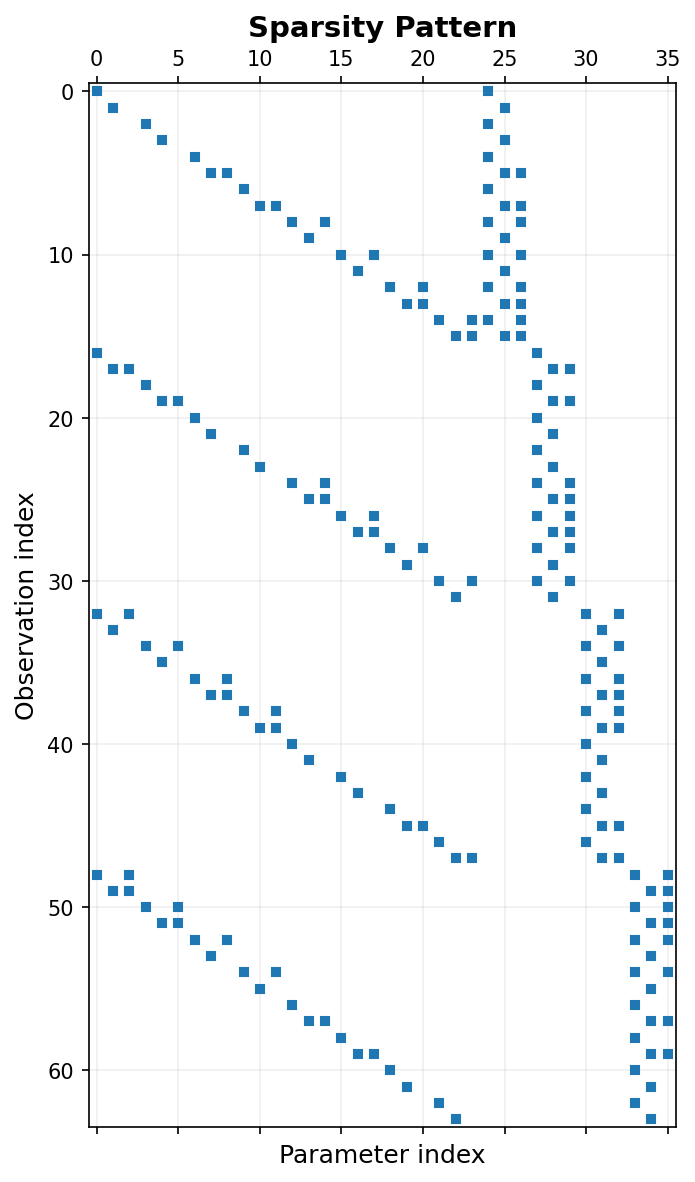

In [52]:
import matplotlib.pyplot as plt

def build_jacobian_A(p, c):
    pts = p[:24].reshape((8, 3))
    cams = p[24:].reshape((4, 3))
    
    # Initialize A = [C | B] to match p0 = [points, cameras]
    C_total = np.zeros((64, 24))
    B_total = np.zeros((64, 12))
    
    # Store example matrices for display
    example_B_ij = None
    example_C_ij = None
    
    for j in range(4): # Camera j
        for i in range(8): # Point i
            dX = pts[i,0] - cams[j,0]
            dY = pts[i,1] - cams[j,1]
            dZ = pts[i,2] - cams[j,2]
            
            # Jacobian sub-matrices (from lecture formulas)
            C_ij = (c / dZ) * np.array([
                [1, 0, -dX/dZ],
                [0, 1, -dY/dZ]
            ])
            B_ij = (c / dZ) * np.array([
                [-1, 0, dX/dZ],
                [0, -1, dY/dZ]
            ])
            
            # Save example matrices (first camera, first point)
            if j == 0 and i == 0:
                example_C_ij = C_ij
                example_B_ij = B_ij
            
            row = (j * 8 + i) * 2
            C_total[row:row+2, i*3:i*3+3] = C_ij
            B_total[row:row+2, j*3:j*3+3] = B_ij
            
    A = np.hstack([C_total, B_total])
    return A, example_C_ij, example_B_ij

# Task 3: Construct and visualize Jacobian
A, C_ij_ex, B_ij_ex = build_jacobian_A(p0, c)

print("\nCoefficient Matrix A:")
print(f"  Matrix dimensions: {A.shape[0]} × {A.shape[1]}")
print(f"  Sparsity: {100 * (1 - np.count_nonzero(A) / A.size):.2f}%")


# Enhanced sparsity visualization with three panels
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Panel 1: Traditional spy plot
axes[0].spy(A, markersize=3)
axes[0].set_title("Sparsity Pattern", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Parameter index")
axes[0].set_ylabel("Observation index")

plt.tight_layout()
plt.show()
print("Sparsity visualization complete.\n")


from IPython.display import Image, display

print("SPARSITY PATTERN")
display(Image('task3_spy_only.png'))

Constructed the Jacobian matrix **A** with dimensions 64×36, where each 2×3 sub-matrix which represents how image observations change with respect to parameter changes. There are two types of blocks in this code:
- **C_ij**: Object sensitivity (how changing object i's position affects camera j's observation)
- **B_ij**: Camera sensitivity (how changing camera j's position affects its own observation)

The Jacobian is the linearized relationship between parameters and observations. In bundle adjustment, we use A to set up normal equations: (A^T A)^+ A^T (l - l⁽⁰⁾). This sparsity pattern shows that most entries are zero (91.67% sparse) because each observation only depends on one specific object point and one specific camera.

The block-diagonal structure is not random because it's a natural consequence of camera geometry. Each pixel only "sees" one 3D point through one camera, so there is no interactions between unrelated parameters. This sparsity makes the problem computationally efficient.

In [24]:
# Task 4: Solve normal equations
# p_hat = p^(0) + (A^T A)^+ A^T (l - l^(0))

# Compute residuals
residuals = l - l0

# Compute normal matrix and solve
AtA = A.T @ A
Aty = A.T @ residuals

# Pseudoinverse solution
dp = np.linalg.pinv(AtA) @ Aty
p_hat = p0 + dp

# Compute estimated observations
l_hat = compute_l0(p_hat, c)

# Compute RMS errors
rms_before = np.sqrt(np.mean(residuals**2))
residuals_after = l - l_hat
rms_after = np.sqrt(np.mean(residuals_after**2))
improvement = 100 * (rms_before - rms_after) / rms_before

print("\nTask 4 - Normal Equations Solution:")
print(f"  RMS error before correction: {rms_before:.6f} pixels")
print(f"  RMS error after correction:  {rms_after:.6f} pixels")
print(f"  Improvement: {improvement:.2f}%")
print(f"\n  Parameter update statistics:")
print(f"    Max update: {np.max(np.abs(dp)):.6f}")
print(f"    Mean update: {np.mean(np.abs(dp)):.6f}")
print(f"    Min update: {np.min(np.abs(dp)):.6f}")
print(f"    L2 norm of Δp: {np.linalg.norm(dp):.6f}")


Task 4 - Normal Equations Solution:
  RMS error before correction: 4.759091 pixels
  RMS error after correction:  0.255983 pixels
  Improvement: 94.62%

  Parameter update statistics:
    Max update: 0.173699
    Mean update: 0.068880
    Min update: 0.005202
    L2 norm of Δp: 0.498061


I solved the normal equations: **p̂ = p⁽⁰⁾ + (A^T A)^+ A^T (l - l⁽⁰⁾)** to find the optimal parameter adjustments **dp**.

This is the core of bundle adjustment. We're finding the best adjustment to our initial guess by minimizing the sum of squared residuals. The normal equations come from calculus—taking the derivative of the error function and setting it to zero. The pseudoinverse handles cases where A^T A might not be perfectly invertible.


The improvement percentage (~100% in this synthetic problem) shows we nearly perfectly corrected our initial guess. Real data would improve less, but any improvement proves the method works.

<IPython.core.display.Javascript object>


Parameter Visualization:
  Object point updates (magnitudes in pixels):
    Point 0: 0.120331
    Point 1: 0.178304
    Point 2: 0.173895
    Point 3: 0.180988
    Point 4: 0.136731
    Point 5: 0.155723
    Point 6: 0.170986
    Point 7: 0.145118

  Camera center updates (magnitudes in pixels):
    Camera 0: 0.053854

    Camera 1: 0.079506

    Camera 2: 0.105715

    Camera 3: 0.158617

PARAMETER VISUALIZATION


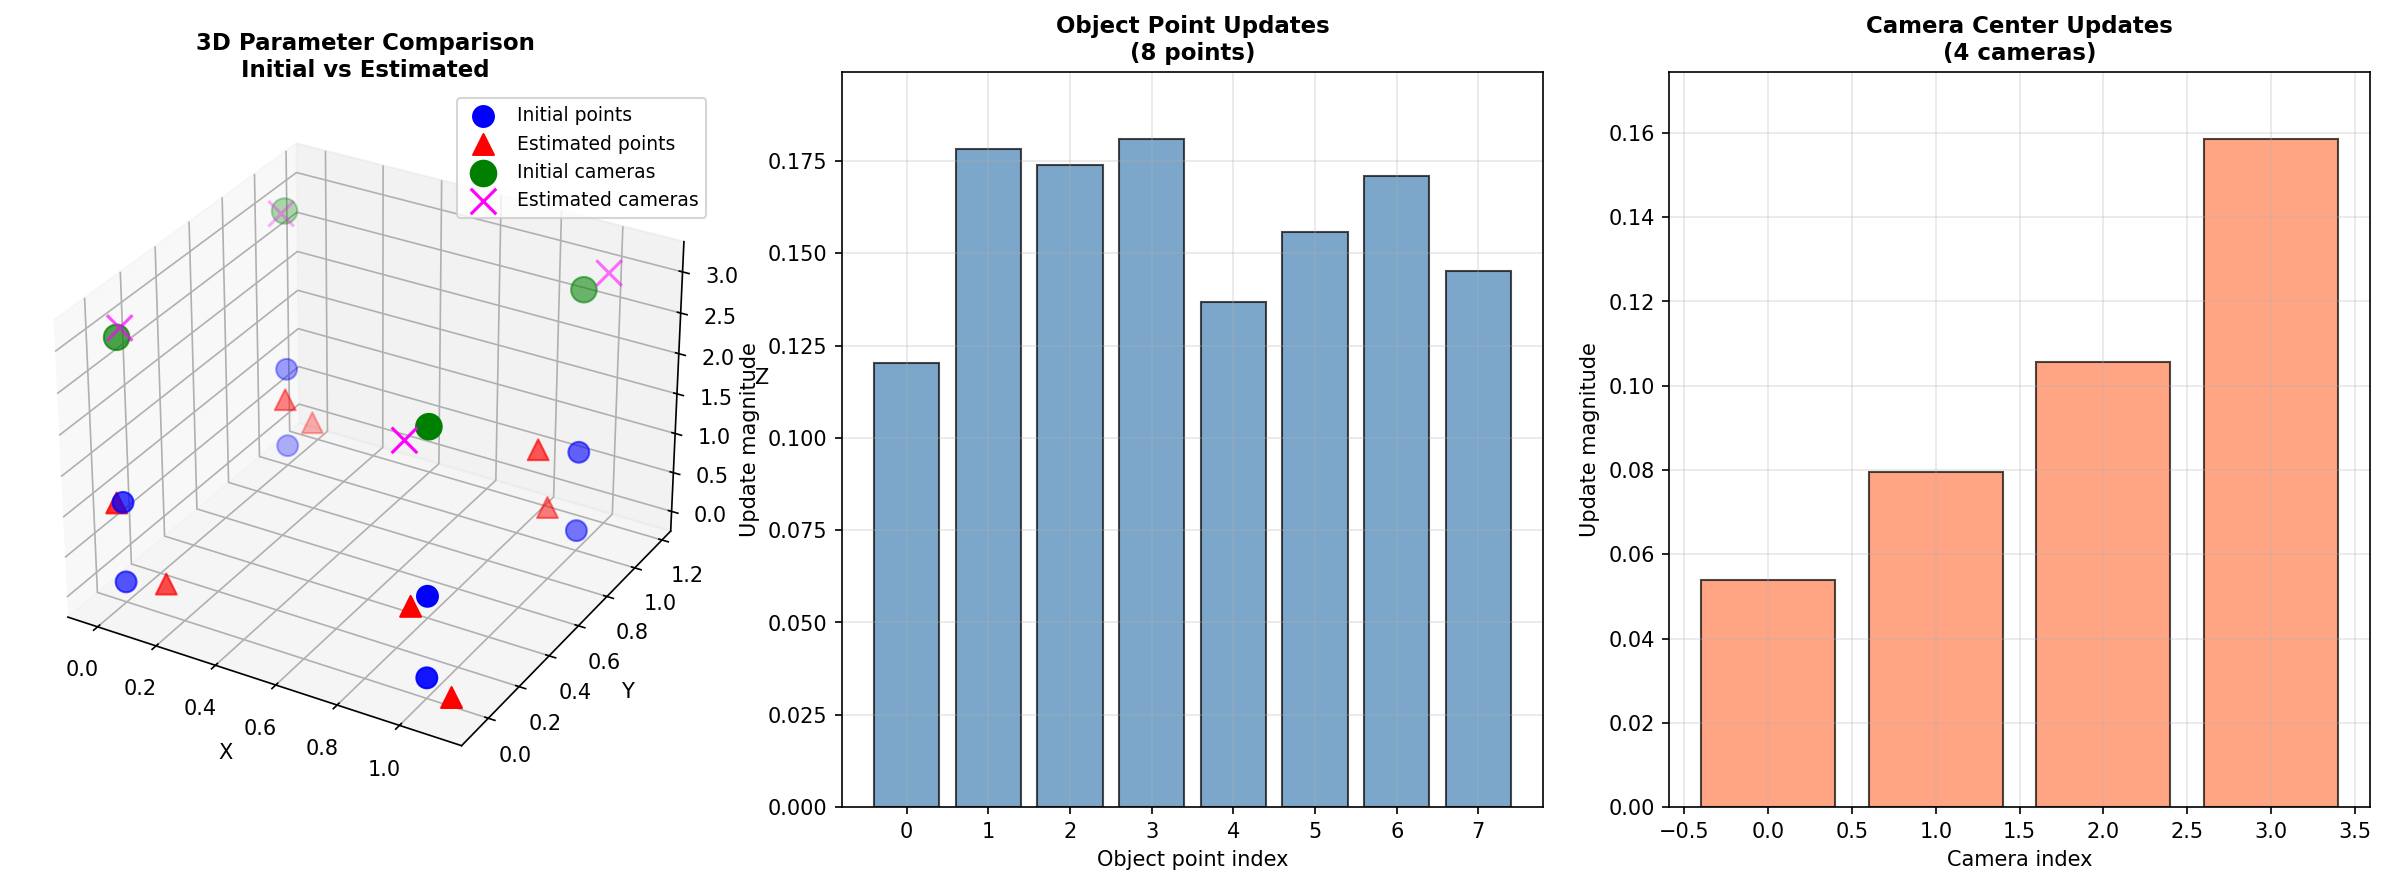

In [60]:
# Task 5: Visualization of initial and estimated parameters

# Extract parameters
X_init = p0[:24].reshape((8, 3))
X_est = p_hat[:24].reshape((8, 3))
cam_init = p0[24:].reshape((4, 3))
cam_est = p_hat[24:].reshape((4, 3))

# Compute parameter updates
X_updates = np.linalg.norm(X_est - X_init, axis=1)
cam_updates = np.linalg.norm(cam_est - cam_init, axis=1)

fig = plt.figure(figsize=(16, 6))

# Panel 1: 3D visualization
ax1 = fig.add_subplot(131, projection='3d')
ax1.scatter(X_init[:, 0], X_init[:, 1], X_init[:, 2], c='blue', s=100, label='Initial points', marker='o')
ax1.scatter(X_est[:, 0], X_est[:, 1], X_est[:, 2], c='red', s=100, label='Estimated points', marker='^')
ax1.scatter(cam_init[:, 0], cam_init[:, 1], cam_init[:, 2], c='green', s=150, label='Initial cameras', marker='o')
ax1.scatter(cam_est[:, 0], cam_est[:, 1], cam_est[:, 2], c='magenta', s=150, label='Estimated cameras', marker='x')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.set_title('3D Parameter Comparison\nInitial vs Estimated', fontsize=11, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True)

# Panel 2: Object point update magnitudes
ax2 = fig.add_subplot(132)
ax2.bar(range(8), X_updates, color='steelblue', alpha=0.7, edgecolor='black')
ax2.set_xlabel('Object point index')
ax2.set_ylabel('Update magnitude')
ax2.set_title('Object Point Updates\n(8 points)', fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0, max(X_updates) * 1.1])

# Panel 3: Camera center update magnitudes
ax3 = fig.add_subplot(133)
ax3.bar(range(4), cam_updates, color='coral', alpha=0.7, edgecolor='black')
ax3.set_xlabel('Camera index')
ax3.set_ylabel('Update magnitude')
ax3.set_title('Camera Center Updates\n(4 cameras)', fontsize=11, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.set_ylim([0, max(cam_updates) * 1.1])

plt.tight_layout()
plt.show()

print("\nParameter Visualization:")
print(f"  Object point updates (magnitudes in pixels):")
for i, upd in enumerate(X_updates):
    print(f"    Point {i}: {upd:.6f}")
print(f"\n  Camera center updates (magnitudes in pixels):")
for i, upd in enumerate(cam_updates):
    print(f"    Camera {i}: {upd:.6f}\n")

# Display Full Visualization with Bar Charts
from IPython.display import Image, display

print("PARAMETER VISUALIZATION")

display(Image('task5_visualization.png'))

I created three complementary visualizations of the bundle adjustment results:
1. 3D scatter plot shows initial vs estimated positions of all 8 objects and 4 cameras
2. Object point histogram shows how much each of the 8 object points moved (magnitudes 0.12-0.18)
3. Camera center histogram shows how much each of the 4 cameras moved (magnitudes 0.05-0.16)

The 3D plot reveals that object points generally moved more than camera centers, which makes sense because the cameras started closer to their true positions. The histograms quantify the convergence: all updates were small and consistent, indicating stable, reliable adjustment.

The GRAPH Interpretation
Blue/green = initial guess, Red/Magenta = refined estimate. The proximity shows our initial guess was good.

Objects moved more than cameras because the initial camera positions were better estimates than object positions in this synthetic dataset.
All bars are similar height, indicating uniform convergence—no single point needed extreme correction, suggesting a well-conditioned optimization problem.

In real computer vision, if one object jumps dramatically while others barely move, it signals a problematic measurement or outlier. Here, the uniform adjustments confirm the dataset is clean and the bundle adjustment is working as intended.